In [9]:
import matplotlib.pyplot as plt
from algorithms.tss_file import TSSFile
import os

In [10]:
def find_file(filename, search_dir):
    for root, dirs, files in os.walk(search_dir):
        if filename in files:
            return root
    return None

In [11]:
folder_a2 = r'Y:\TESTDATA\DP\2025\12'
tss_file_a2 = 'Tek20251217T100124.tss'
folder_a3 = r'Y:\TESTDATA\DP\2026\07'
tss_file_a31 = 'Tek20260706T154634.tss'
tss_file_a32 = 'Tek20260706T152912.tss'
path_a2 = find_file(tss_file_a2, folder_a2)
path_a31 = find_file(tss_file_a31, folder_a3)
path_a32 = find_file(tss_file_a32, folder_a3)
tss_a2 = TSSFile(path_a2, tss_file_a2, source='Local')
tss_a31 = TSSFile(path_a31, tss_file_a31, source='Local')
tss_a32 = TSSFile(path_a32, tss_file_a32, source='Local')
"""channel_labels = tss.channel_labels
num = len(channel_labels.keys())
print(channel_labels)"""

'channel_labels = tss.channel_labels\nnum = len(channel_labels.keys())\nprint(channel_labels)'

In [15]:
channels_to_plot = ['Vd', 'Is', 'Vg', 'Ig']
a2_channels = {'Vd': 'ch3', 'Is': 'ch2', 'Vg': 'ch1', 'Ig': 'ch5'}
a3_channels = {'Vd': 'ch3', 'Is': 'ch6', 'Vg': 'ch1', 'Ig': 'ch5'}

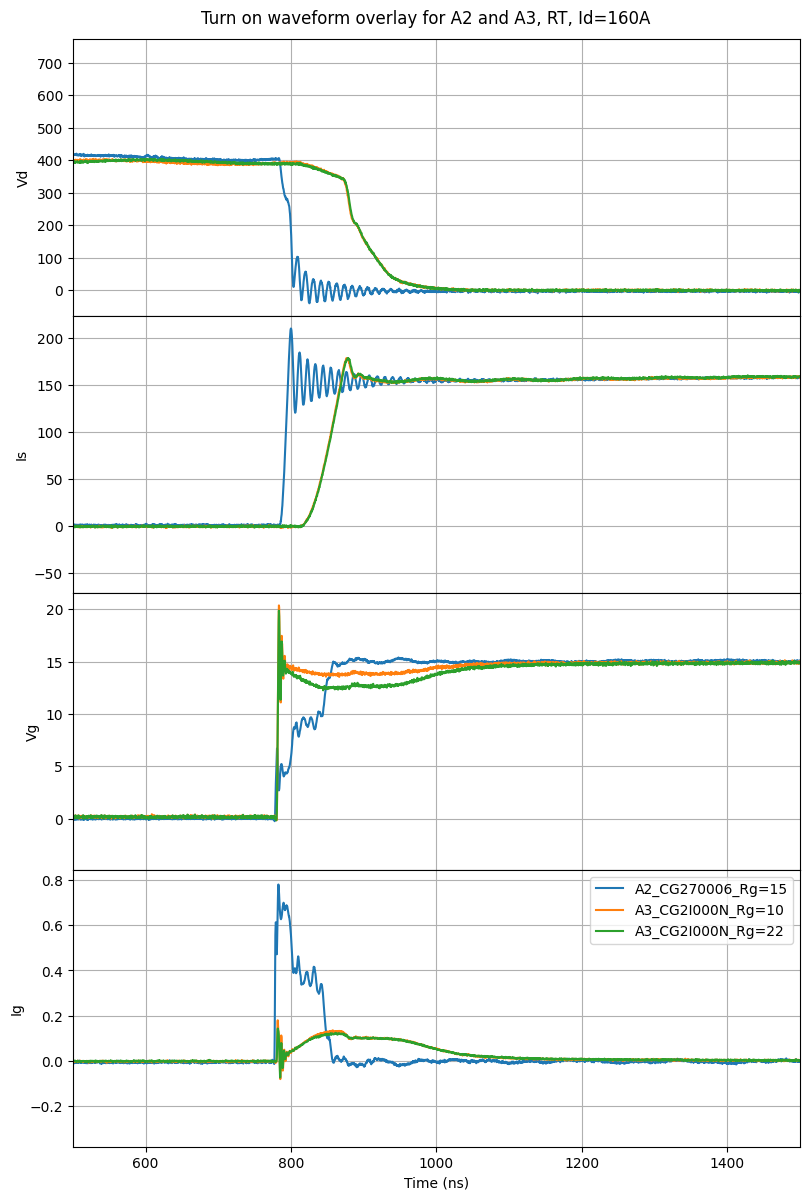

In [23]:
fig, axs = plt.subplots(4, 1, sharex=True, figsize=(8, 4*3))
fig.suptitle('Turn on waveform overlay for A2 and A3, RT, Id=160A')
fig.tight_layout()
fig.subplots_adjust(hspace=0)
time_a2 = tss_a2.waveforms['ch1'].time_for_frame()*1e9
time_a31 = tss_a31.waveforms['ch1'].time_for_frame()*1e9 - 470
time_a32 = tss_a32.waveforms['ch1'].time_for_frame()*1e9 - 470

for i in [0]:
    index = 0
    for label in channels_to_plot:
        values = tss_a2.waveforms[a2_channels[label]].values_for_frame(i)
        axs[index].plot(time_a2, values, label='A2_CG270006_Rg=15')

        values = tss_a31.waveforms[a3_channels[label]].values_for_frame(i)
        axs[index].plot(time_a31, values, label='A3_CG2I000N_Rg=10')

        values = tss_a32.waveforms[a3_channels[label]].values_for_frame(i)
        axs[index].plot(time_a32, values, label='A3_CG2I000N_Rg=22')
        axs[index].set_ylabel(label)
        axs[index].grid(True)
        index += 1

plt.legend()
plt.xlabel('Time (ns)')
plt.xlim([500, 1500])
plt.legend(loc='best')
plt.show()